In [ ]:

import os
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    roc_curve,
    auc
)

print("All required libraries imported successfully!")


All required libraries imported successfully!


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

zip_path = "/content/drive/MyDrive/AI IN MEDICINE DATASET/archive (1).zip"

if os.path.isfile(zip_path):
    print("Dataset ZIP found successfully!")
    print("File size:", round(os.path.getsize(zip_path) / (1024**2), 2), "MB")
else:
    print("Dataset ZIP not found at the expected path.")
    print("Please check the ZIP file location in Google Drive.")


Dataset ZIP found successfully!
File size: 1552.5 MB


In [ ]:

import os
import zipfile

zip_path = "/content/drive/MyDrive/AI IN MEDICINE DATASET/archive (1).zip"
extract_path = "/content/kidney_dataset"

if not os.path.isfile(zip_path):
    raise FileNotFoundError(
        f"ZIP file not found: {zip_path}\n"
        "Check the file location in Google Drive."
    )

os.makedirs(extract_path, exist_ok=True)

if not os.listdir(extract_path):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

print("Dataset extraction completed!")
print("Extraction location:", extract_path)
print("Top-level folders:", os.listdir(extract_path)[:15])


Dataset extraction completed!
Extraction location: /content/kidney_dataset
Top-level folders: ['CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone', 'kidneyData.csv']


In [ ]:

required_classes = ["Normal", "Cyst", "Tumor", "Stone"]

dataset_root = None

for current_root, dirs, files in os.walk(extract_path):
    if all(class_name in dirs for class_name in required_classes):
        dataset_root = current_root
        break

if dataset_root is None:
    print("Could not find all four class folders.")
    print("Please share the output of:")
    print("os.listdir('/content/kidney_dataset')")
else:
    print("Dataset root found:", dataset_root)
    print("Class folders:", os.listdir(dataset_root))


Dataset root found: /content/kidney_dataset/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone
Class folders: ['Normal', 'Cyst', 'Stone', 'Tumor']


In [ ]:

from collections import Counter

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

class_counts = {}

for class_name in required_classes:
    class_path = os.path.join(dataset_root, class_name)

    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(valid_extensions)
        and os.path.isfile(os.path.join(class_path, file))
    ]

    class_counts[class_name] = len(image_files)

print("ORIGINAL DATASET DISTRIBUTION")
print("-" * 35)

for class_name, count in class_counts.items():
    print(f"{class_name}: {count} images")

print("-" * 35)
print("Total images:", sum(class_counts.values()))


ORIGINAL DATASET DISTRIBUTION
-----------------------------------
Normal: 5077 images
Cyst: 3709 images
Tumor: 2283 images
Stone: 1377 images
-----------------------------------
Total images: 12446


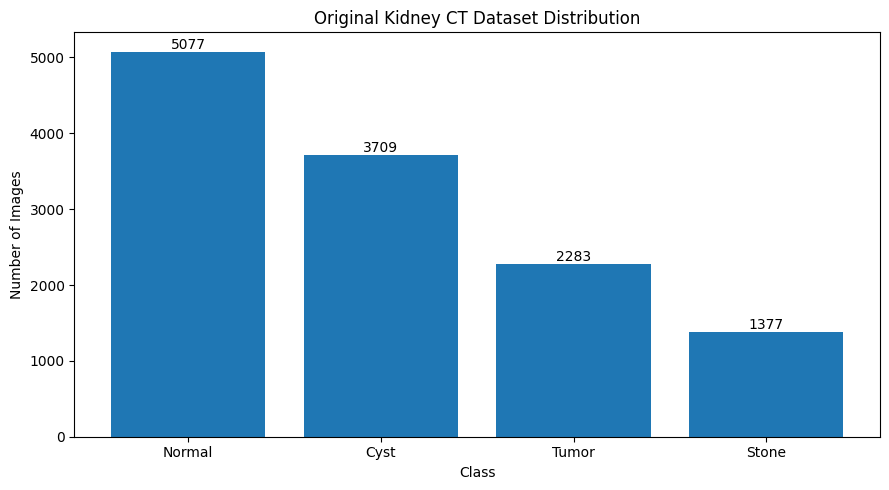

In [ ]:

import matplotlib.pyplot as plt

class_names = ["Normal", "Cyst", "Tumor", "Stone"]

counts = [
    class_counts[class_name]
    for class_name in class_names
]

plt.figure(figsize=(9, 5))

bars = plt.bar(class_names, counts)

plt.title("Original Kidney CT Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [ ]:
!pip install pillow

In [ ]:

import os
import pandas as pd

class_names = ["Normal", "Cyst", "Tumor", "Stone"]

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

data = []

for class_name in class_names:
    class_path = os.path.join(dataset_root, class_name)

    for file_name in os.listdir(class_path):
        image_path = os.path.join(class_path, file_name)

        if (
            file_name.lower().endswith(image_extensions)
            and os.path.isfile(image_path)
        ):
            data.append({
                "image_path": image_path,
                "class": class_name
            })

df = pd.DataFrame(data)

print("Total images collected:", len(df))
print("\nImages per class:")
print(df["class"].value_counts().reindex(class_names))
print("\nFirst five records:")
print(df.head())


Total images collected: 12446

Images per class:
class
Normal    5077
Cyst      3709
Tumor     2283
Stone     1377
Name: count, dtype: int64

First five records:
                                          image_path   class
0  /content/kidney_dataset/CT-KIDNEY-DATASET-Norm...  Normal
1  /content/kidney_dataset/CT-KIDNEY-DATASET-Norm...  Normal
2  /content/kidney_dataset/CT-KIDNEY-DATASET-Norm...  Normal
3  /content/kidney_dataset/CT-KIDNEY-DATASET-Norm...  Normal
4  /content/kidney_dataset/CT-KIDNEY-DATASET-Norm...  Normal


In [ ]:

from sklearn.model_selection import train_test_split

# First: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["class"]
)

# Second: split temporary set equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["class"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))


Training images: 8712
Validation images: 1867
Test images: 1867
Total: 12446


In [ ]:

print("TRAINING SET")
print(train_df["class"].value_counts().reindex(class_names))

print("\nVALIDATION SET")
print(val_df["class"].value_counts().reindex(class_names))

print("\nTEST SET")
print(test_df["class"].value_counts().reindex(class_names))


TRAINING SET
class
Normal    3554
Cyst      2596
Tumor     1598
Stone      964
Name: count, dtype: int64

VALIDATION SET
class
Normal    762
Cyst      556
Tumor     343
Stone     206
Name: count, dtype: int64

TEST SET
class
Normal    761
Cyst      557
Tumor     342
Stone     207
Name: count, dtype: int64


In [ ]:

IMG_SIZE = 128
BATCH_SIZE = 32
CHANNELS = 3
LATENT_DIM = 100

print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Channels:", CHANNELS)
print("Latent dimension:", LATENT_DIM)


Image size: 128 x 128
Batch size: 32
Channels: 3
Latent dimension: 100


In [ ]:

import tensorflow as tf

def load_gan_image(image_path):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    # Convert pixel range from [0, 255] to [-1, 1]
    image = (image / 127.5) - 1.0

    return image


In [ ]:

train_paths = train_df["image_path"].values

gan_train_dataset = tf.data.Dataset.from_tensor_slices(
    train_paths
)

gan_train_dataset = gan_train_dataset.map(
    load_gan_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

gan_train_dataset = gan_train_dataset.shuffle(
    buffer_size=min(len(train_paths), 2000),
    seed=42
)

gan_train_dataset = gan_train_dataset.batch(
    BATCH_SIZE,
    drop_remainder=True
)

gan_train_dataset = gan_train_dataset.prefetch(
    tf.data.AUTOTUNE
)

print("GAN training pipeline created successfully!")
print("Number of training images:", len(train_paths))


GAN training pipeline created successfully!
Number of training images: 8712


Batch shape: (32, 128, 128, 3)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


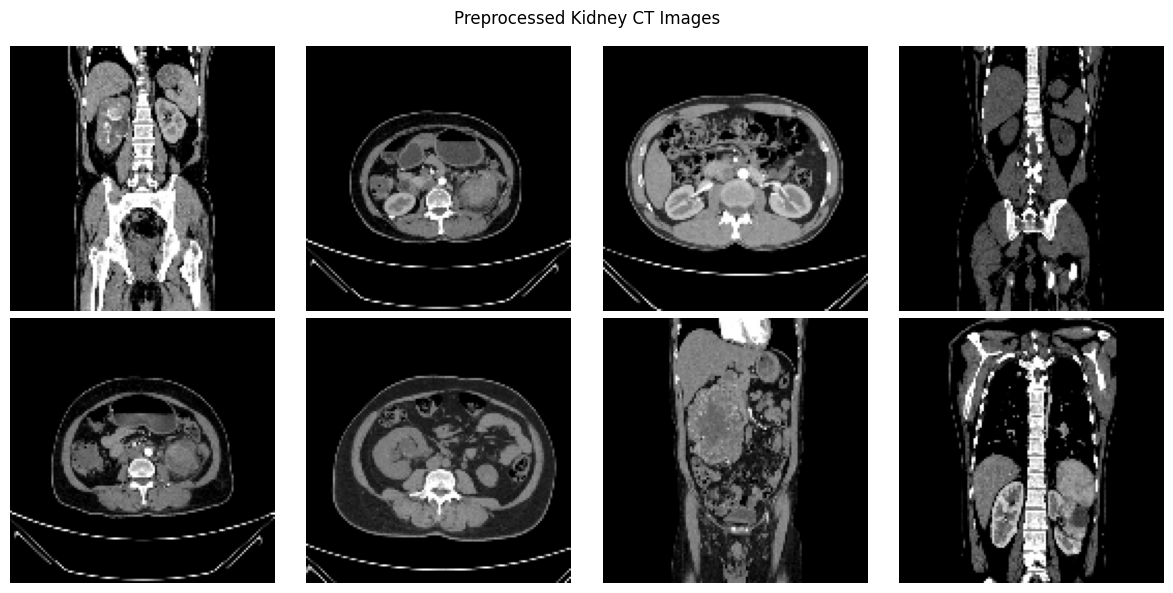

In [ ]:

for batch in gan_train_dataset.take(1):

    print("Batch shape:", batch.shape)
    print("Minimum pixel value:", tf.reduce_min(batch).numpy())
    print("Maximum pixel value:", tf.reduce_max(batch).numpy())

    # Convert [-1, 1] back to [0, 1] for display
    display_images = (batch[:8] + 1.0) / 2.0

    plt.figure(figsize=(12, 6))

    for i in range(min(8, display_images.shape[0])):
        plt.subplot(2, 4, i + 1)
        plt.imshow(display_images[i].numpy())
        plt.axis("off")

    plt.suptitle("Preprocessed Kidney CT Images")
    plt.tight_layout()
    plt.show()


In [ ]:

from tensorflow.keras import layers, Model

def build_generator():

    inputs = layers.Input(shape=(LATENT_DIM,))

    # 100-dimensional noise -> 8 x 8 x 512
    x = layers.Dense(8 * 8 * 512, use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    x = layers.Reshape((8, 8, 512))(x)

    # 8 x 8 -> 16 x 16
    x = layers.Conv2DTranspose(
        256, kernel_size=4, strides=2,
        padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    # 16 x 16 -> 32 x 32
    x = layers.Conv2DTranspose(
        128, kernel_size=4, strides=2,
        padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    # 32 x 32 -> 64 x 64
    x = layers.Conv2DTranspose(
        64, kernel_size=4, strides=2,
        padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    # 64 x 64 -> 128 x 128
    outputs = layers.Conv2DTranspose(
        3, kernel_size=4, strides=2,
        padding="same", activation="tanh"
    )(x)

    return Model(inputs, outputs, name="Generator")


generator = build_generator()

generator.summary()


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32768)          │     3,276,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32768)          │       131,072 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 256)    │     2,097,152 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 128, 128, 3)    │         3,075 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,165,251 (23.52 MB)

 Trainable params: 6,098,819 (23.27 MB)

 Non-trainable params: 66,432 (259.50 KB)

In [ ]:

def build_discriminator():

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS))

    x = layers.Conv2D(
        64, kernel_size=4, strides=2,
        padding="same"
    )(inputs)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(
        128, kernel_size=4, strides=2,
        padding="same"
    )(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(
        256, kernel_size=4, strides=2,
        padding="same"
    )(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(
        512, kernel_size=4, strides=2,
        padding="same"
    )(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Flatten()(x)
    outputs = layers.Dense(1)(x)

    return Model(inputs, outputs, name="Discriminator")


discriminator = build_discriminator()

discriminator.summary()


Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 256)    │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 512)      │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        32,769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,789,313 (10.64 MB)

 Trainable params: 2,789,313 (10.64 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Generate one batch of random noise
sample_noise = tf.random.normal([4, LATENT_DIM])

# Generate synthetic images
sample_generated_images = generator(
    sample_noise,
    training=False
)

# Pass generated images through Discriminator
sample_scores = discriminator(
    sample_generated_images,
    training=False
)

print("Generator output shape:", sample_generated_images.shape)
print("Discriminator output shape:", sample_scores.shape)
print("Synthetic image pixel range:",
      tf.reduce_min(sample_generated_images).numpy(),
      "to",
      tf.reduce_max(sample_generated_images).numpy())


Generator output shape: (4, 128, 128, 3)
Discriminator output shape: (4, 1)
Synthetic image pixel range: -0.012267696 to 0.010507494


In [ ]:

# Binary cross-entropy loss
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

# Generator loss
def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

# Discriminator loss
def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss


In [ ]:

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

print("Generator optimizer:", generator_optimizer)
print("Discriminator optimizer:", discriminator_optimizer)


Generator optimizer: <keras.src.optimizers.adam.Adam object at 0x7e674e8ad2b0>
Discriminator optimizer: <keras.src.optimizers.adam.Adam object at 0x7e6700e542d0>


In [ ]:

EPOCHS = 50

noise_dim = LATENT_DIM

num_examples_to_generate = 16

# Fixed noise lets us compare generated images across epochs
seed = tf.random.normal(
    [num_examples_to_generate, noise_dim],
    seed=42
)

print("Epochs:", EPOCHS)
print("Latent dimension:", noise_dim)
print("Images per preview:", num_examples_to_generate)


Epochs: 50
Latent dimension: 100
Images per preview: 16


In [ ]:

@tf.function
def train_step(real_images):

    batch_size = tf.shape(real_images)[0]

    # Generate random noise
    noise = tf.random.normal(
        [batch_size, LATENT_DIM]
    )

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        # Generate synthetic images
        fake_images = generator(
            noise,
            training=True
        )

        # Discriminator scores
        real_output = discriminator(
            real_images,
            training=True
        )

        fake_output = discriminator(
            fake_images,
            training=True
        )

        # Calculate losses
        gen_loss = generator_loss(fake_output)

        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    # Calculate gradients
    gradients_of_generator = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    # Update model weights
    generator_optimizer.apply_gradients(
        zip(
            gradients_of_generator,
            generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            gradients_of_discriminator,
            discriminator.trainable_variables
        )
    )

    return gen_loss, disc_loss


print("GAN training step defined successfully!")


GAN training step defined successfully!


In [ ]:

def generate_and_save_images(model, epoch, test_input):

    predictions = model(
        test_input,
        training=False
    )

    # Convert [-1, 1] to [0, 1]
    predictions = (predictions + 1.0) / 2.0

    predictions = tf.clip_by_value(
        predictions, 0.0, 1.0
    )

    plt.figure(figsize=(8, 8))

    for i in range(predictions.shape[0]):

        plt.subplot(4, 4, i + 1)

        plt.imshow(predictions[i].numpy())
        plt.axis("off")

    plt.suptitle(
        f"Synthetic Kidney CT Images - Epoch {epoch}"
    )

    plt.tight_layout()
    plt.show()


In [ ]:

import time

# Use 5 epochs for the first test run
TEST_EPOCHS = 5

generator_losses = []
discriminator_losses = []

for epoch in range(1, TEST_EPOCHS + 1):

    start_time = time.time()

    epoch_gen_loss = tf.keras.metrics.Mean()
    epoch_disc_loss = tf.keras.metrics.Mean()

    for batch_images in gan_train_dataset:

        gen_loss, disc_loss = train_step(
            batch_images
        )

        epoch_gen_loss.update_state(gen_loss)
        epoch_disc_loss.update_state(disc_loss)

    avg_gen_loss = epoch_gen_loss.result().numpy()
    avg_disc_loss = epoch_disc_loss.result().numpy()

    generator_losses.append(avg_gen_loss)
    discriminator_losses.append(avg_disc_loss)

    print(
        f"Epoch {epoch}/{TEST_EPOCHS} | "
        f"Generator Loss: {avg_gen_loss:.4f} | "
        f"Discriminator Loss: {avg_disc_loss:.4f} | "
        f"Time: {time.time() - start_time:.1f}s"
    )

    # Display generated samples after every epoch
    generate_and_save_images(
        generator,
        epoch,
        seed
    )

print("Initial GAN training completed!")


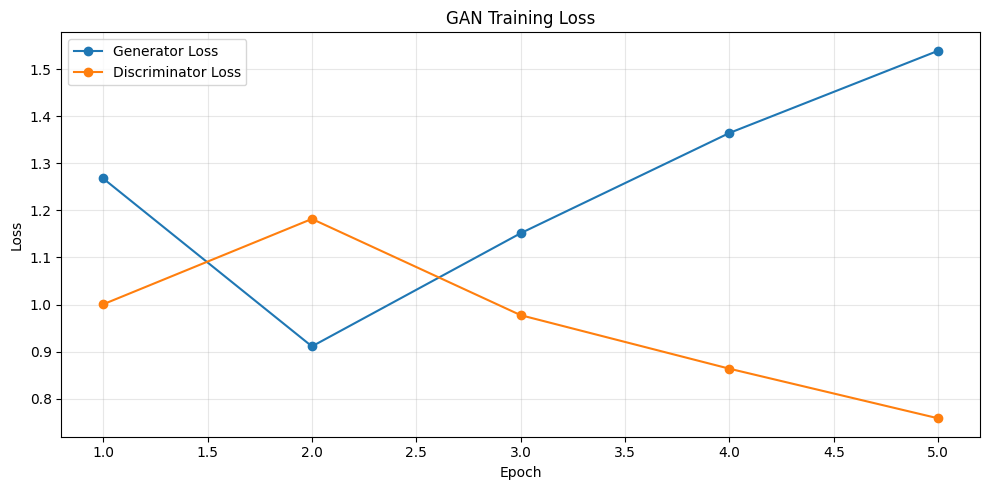

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(generator_losses) + 1),
    generator_losses,
    marker="o",
    label="Generator Loss"
)

plt.plot(
    range(1, len(discriminator_losses) + 1),
    discriminator_losses,
    marker="o",
    label="Discriminator Loss"
)

plt.title("GAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


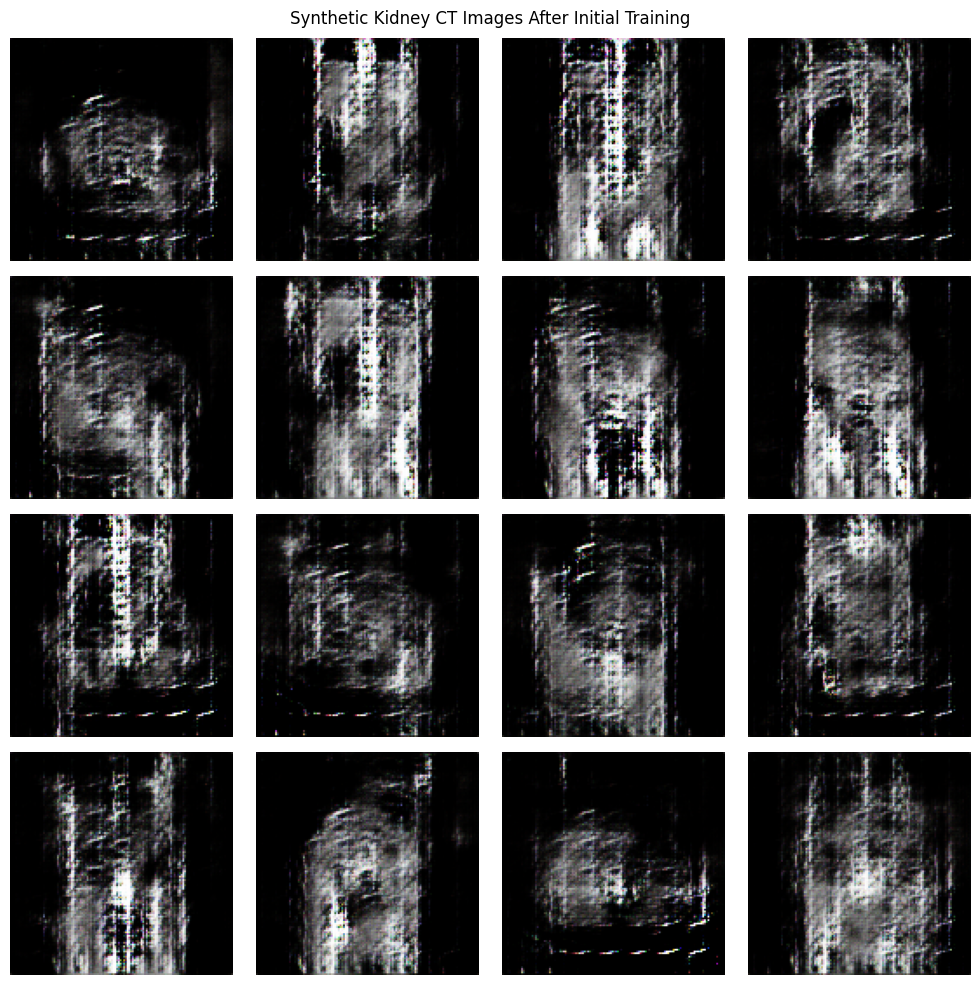

Generated image shape: (16, 128, 128, 3)
Generator output range: -1.0 to 0.9999906420707703


In [ ]:

num_images = 16

noise = tf.random.normal(
    [num_images, LATENT_DIM]
)

gan_images = generator(
    noise,
    training=False
)

# Convert [-1, 1] to [0, 1]
gan_images_display = (gan_images + 1.0) / 2.0

gan_images_display = tf.clip_by_value(
    gan_images_display, 0.0, 1.0
)

plt.figure(figsize=(10, 10))

for i in range(num_images):
    plt.subplot(4, 4, i + 1)

    plt.imshow(gan_images_display[i].numpy())
    plt.axis("off")

plt.suptitle("Synthetic Kidney CT Images After Initial Training")
plt.tight_layout()
plt.show()

print("Generated image shape:", gan_images.shape)
print(
    "Generator output range:",
    float(tf.reduce_min(gan_images)),
    "to",
    float(tf.reduce_max(gan_images))
)


In [ ]:

generator_save_path = (
    "/content/drive/MyDrive/kidney_generator.keras"
)

generator.save(generator_save_path)

print("Generator saved successfully!")
print("Location:", generator_save_path)


Generator saved successfully!
Location: /content/drive/MyDrive/kidney_generator.keras


In [ ]:

import os

synthetic_dir = (
    "/content/drive/MyDrive/Kidney_CT_Project/Synthetic_Images"
)

os.makedirs(synthetic_dir, exist_ok=True)

print("Synthetic image folder created:")
print(synthetic_dir)


Synthetic image folder created:
/content/drive/MyDrive/Kidney_CT_Project/Synthetic_Images


In [ ]:

import numpy as np
from PIL import Image

NUM_SYNTHETIC_IMAGES = 100
saved_count = 0

for start in range(0, NUM_SYNTHETIC_IMAGES, BATCH_SIZE):

    current_batch_size = min(
        BATCH_SIZE,
        NUM_SYNTHETIC_IMAGES - start
    )

    noise = tf.random.normal(
        [current_batch_size, LATENT_DIM]
    )

    generated_images = generator(
        noise,
        training=False
    )

    # Convert [-1, 1] to [0, 255]
    generated_images = (generated_images + 1.0) * 127.5

    generated_images = tf.clip_by_value(
        generated_images, 0, 255
    )

    generated_images = generated_images.numpy().astype(
        np.uint8
    )

    for i, image_array in enumerate(generated_images):

        image_number = start + i + 1

        image_path = os.path.join(
            synthetic_dir,
            f"synthetic_{image_number:04d}.png"
        )

        Image.fromarray(image_array).save(image_path)

        saved_count += 1

print("Synthetic images saved:", saved_count)
print("Saved folder:", synthetic_dir)


Synthetic images saved: 100
Saved folder: /content/drive/MyDrive/Kidney_CT_Project/Synthetic_Images


In [ ]:

saved_images = [
    file for file in os.listdir(synthetic_dir)
    if file.lower().endswith(".png")
]

print("Total saved PNG images:", len(saved_images))
print("First 10 files:", saved_images[:10])


Total saved PNG images: 100
First 10 files: ['synthetic_0001.png', 'synthetic_0002.png', 'synthetic_0003.png', 'synthetic_0004.png', 'synthetic_0005.png', 'synthetic_0006.png', 'synthetic_0007.png', 'synthetic_0008.png', 'synthetic_0009.png', 'synthetic_0010.png']


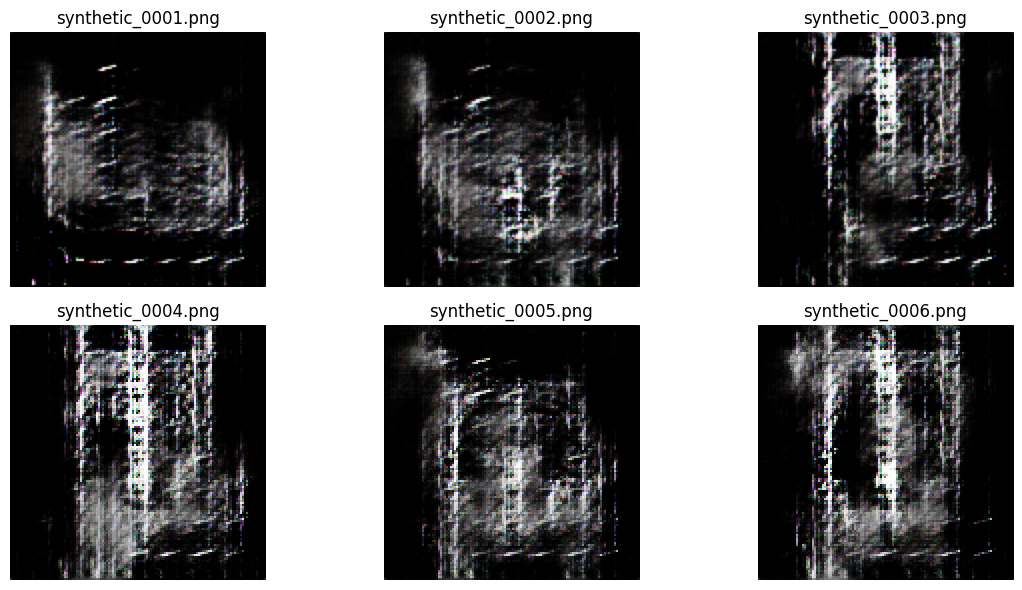

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

sample_files = sorted(saved_images)[:6]

plt.figure(figsize=(12, 6))

for i, file_name in enumerate(sample_files):

    image_path = os.path.join(synthetic_dir, file_name)
    image = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(file_name)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

CLASS_IMG_SIZE = 224
CLASS_BATCH_SIZE = 32
NUM_CLASSES = 4

class_names = ["Normal", "Cyst", "Tumor", "Stone"]

class_to_label = {
    "Normal": 0,
    "Cyst": 1,
    "Tumor": 2,
    "Stone": 3
}

train_df["label"] = train_df["class"].map(class_to_label)
val_df["label"] = val_df["class"].map(class_to_label)
test_df["label"] = test_df["class"].map(class_to_label)

print("Classification parameters ready!")
print("Classes:", class_names)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))


Classification parameters ready!
Classes: ['Normal', 'Cyst', 'Tumor', 'Stone']
Training images: 8712
Validation images: 1867
Test images: 1867


In [ ]:

def load_classification_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [CLASS_IMG_SIZE, CLASS_IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.int32)


In [ ]:

AUTOTUNE = tf.data.AUTOTUNE

def create_classification_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_classification_image,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 2000),
            seed=42
        )

    dataset = dataset.batch(CLASS_BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_dataset = create_classification_dataset(
    train_df, training=True
)

val_dataset = create_classification_dataset(
    val_df
)

test_dataset = create_classification_dataset(
    test_df
)

print("Classification datasets created successfully!")

for images, labels in train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))


Classification datasets created successfully!
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 255.0


In [ ]:

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

# Load pretrained EfficientNetB0
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(CLASS_IMG_SIZE, CLASS_IMG_SIZE, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build classification head
inputs = layers.Input(
    shape=(CLASS_IMG_SIZE, CLASS_IMG_SIZE, 3)
)

# Conservative augmentation for training images
x = layers.RandomRotation(0.05)(inputs)
x = layers.RandomZoom(0.10)(x)

# EfficientNetB0 includes its own input rescaling
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(inputs, outputs, name="Kidney_EfficientNetB0")

print("EfficientNetB0 model created!")


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 model created!


In [ ]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0002
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "Kidney_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["label"].to_numpy()
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("Class weights:")
for i, class_name in enumerate(class_names):
    print(f"{class_name}: {class_weights[i]:.4f}")


Class weights:
Normal: 0.6128
Cyst: 0.8390
Tumor: 1.3630
Stone: 2.2593


In [ ]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_kidney_classifier.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 53s 129ms/step - accuracy: 0.4190 - loss: 1.2589 - val_accuracy: 0.5903 - val_loss: 1.0367 - learning_rate: 2.0000e-04
Epoch 2/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 38s 117ms/step - accuracy: 0.6252 - loss: 0.9707 - val_accuracy: 0.6224 - val_loss: 0.9022 - learning_rate: 2.0000e-04
Epoch 3/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 41s 133ms/step - accuracy: 0.6920 - loss: 0.8359 - val_accuracy: 0.6540 - val_loss: 0.8276 - learning_rate: 2.0000e-04
Epoch 4/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 39s 125ms/step - accuracy: 0.7165 - loss: 0.7600 - val_accuracy: 0.6674 - val_loss: 0.7726 - learning_rate: 2.0000e-04
Epoch 5/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 40s 120ms/step - accuracy: 0.7482 - loss: 0.7050 - val_accuracy: 0.6690 - val_loss: 0.7670 - learning_rate: 2.0000e-04
Epoch 6/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 40s 118ms/step - accuracy: 0.7576 - loss: 0.6690 - val_accuracy: 0.6808 - val_loss: 0.7321 - learning_rate: 2.0000e-04
Epoch 7/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 41s 11

In [ ]:

test_loss, test_accuracy = model.evaluate(
    test_dataset,
    verbose=1
)

print("\n========== TEST RESULTS ==========")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")


59/59 ━━━━━━━━━━━━━━━━━━━━ 10s 162ms/step - accuracy: 0.6926 - loss: 0.6905

========== TEST RESULTS ==========
Test Loss     : 0.6905
Test Accuracy : 69.26%


In [ ]:

import numpy as np
from sklearn.metrics import classification_report

y_true = []
y_prob = []

for images, labels in test_dataset:
    probabilities = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_prob.extend(probabilities)

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = np.argmax(y_prob, axis=1)

print("CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


CLASSIFICATION REPORT

              precision    recall  f1-score   support

      Normal     0.9470    0.5874    0.7251       761
        Cyst     0.7349    0.9156    0.8153       557
       Tumor     0.8756    0.5146    0.6483       342
       Stone     0.3200    0.7729    0.4526       207

    accuracy                         0.6926      1867
   macro avg     0.7194    0.6976    0.6603      1867
weighted avg     0.8011    0.6926    0.7077      1867



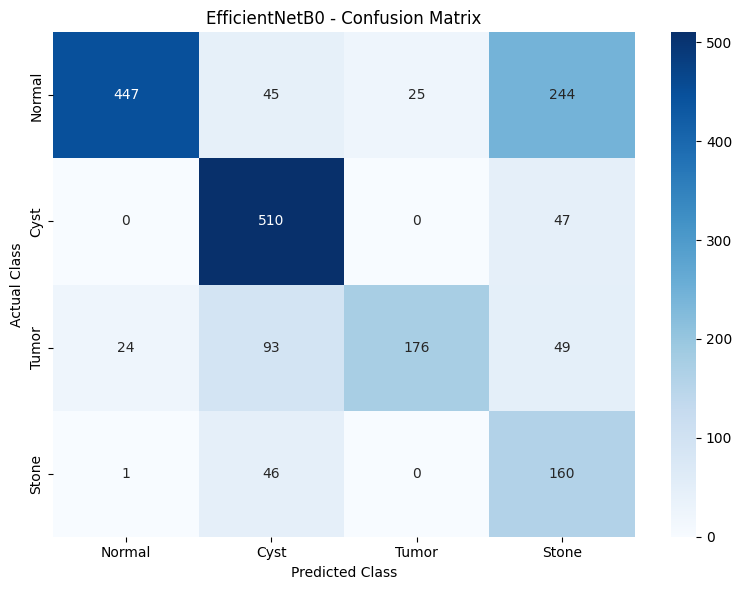

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("EfficientNetB0 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


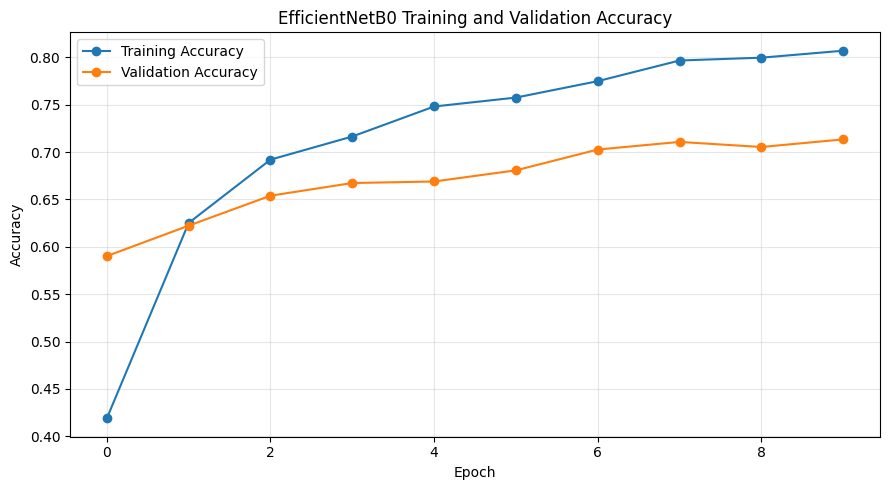

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("EfficientNetB0 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


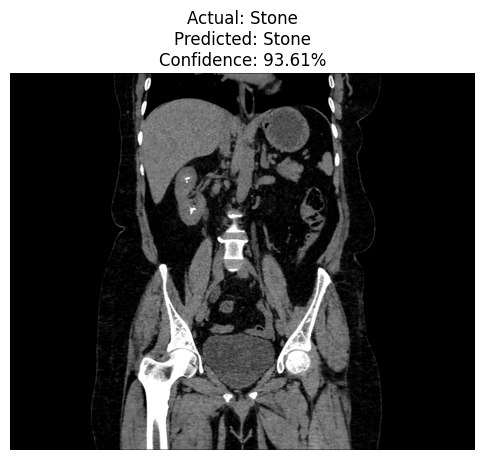

Actual class     : Stone
Predicted class  : Stone
Prediction confidence: 93.61%
Prediction correct: True


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

# Select one real image from the test dataset
sample = test_df.sample(n=1, random_state=42).iloc[0]

image_path = sample["image_path"]
actual_class = sample["class"]

# Load and preprocess image
image = Image.open(image_path).convert("RGB")
image_resized = image.resize((CLASS_IMG_SIZE, CLASS_IMG_SIZE))

image_array = np.array(
    image_resized,
    dtype=np.float32
)

input_image = np.expand_dims(image_array, axis=0)

# Predict
probabilities = model.predict(input_image, verbose=0)[0]

predicted_index = int(np.argmax(probabilities))
predicted_class = class_names[predicted_index]
confidence = float(probabilities[predicted_index]) * 100

# Display result
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Actual: {actual_class}\n"
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Actual class     :", actual_class)
print("Predicted class  :", predicted_class)
print(f"Prediction confidence: {confidence:.2f}%")
print(
    "Prediction correct:",
    predicted_class == actual_class
)


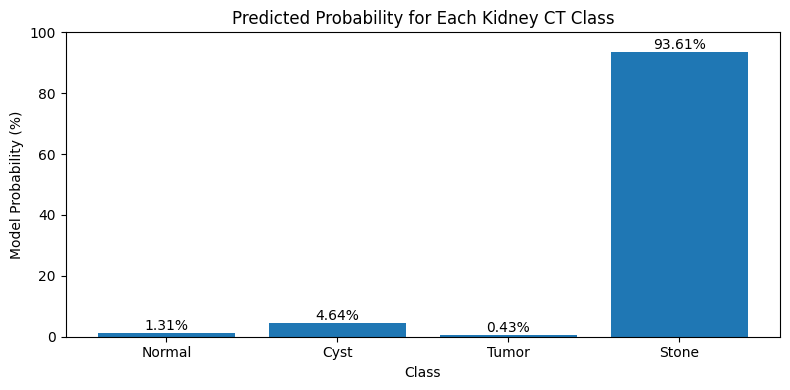

In [ ]:

plt.figure(figsize=(8, 4))

bars = plt.bar(
    class_names,
    probabilities * 100
)

plt.title("Predicted Probability for Each Kidney CT Class")
plt.xlabel("Class")
plt.ylabel("Model Probability (%)")
plt.ylim(0, 100)

for bar, probability in zip(bars, probabilities):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{probability * 100:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


Saving Cyst- (2).jpg to Cyst- (2).jpg


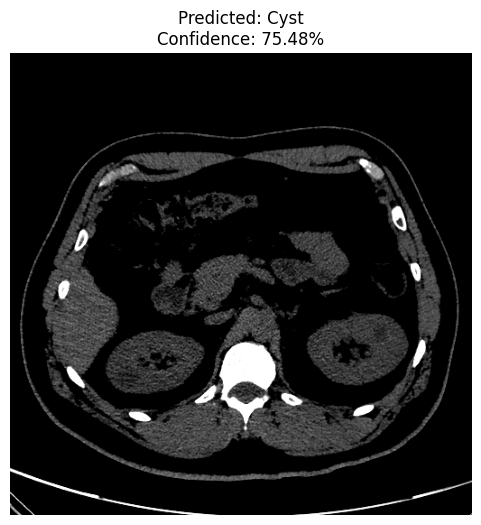

Predicted class: Cyst
Confidence: 75.48%
Normal: 0.15%
Cyst: 75.48%
Tumor: 0.23%
Stone: 24.15%


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

for file_name in uploaded.keys():

    image = Image.open(file_name).convert("RGB")
    image_resized = image.resize(
        (CLASS_IMG_SIZE, CLASS_IMG_SIZE)
    )

    input_image = np.expand_dims(
        np.array(image_resized, dtype=np.float32),
        axis=0
    )

    probabilities = model.predict(
        input_image,
        verbose=0
    )[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = class_names[predicted_index]
    confidence = float(probabilities[predicted_index]) * 100

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Predicted class:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")

    for name, probability in zip(class_names, probabilities):
        print(f"{name}: {probability * 100:.2f}%")


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import numpy as np

# Overall test accuracy
overall_accuracy = accuracy_score(y_true, y_pred)

# Overall classification metrics
overall_precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

overall_recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

overall_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# Overall multiclass ROC-AUC
y_true_one_hot = tf.keras.utils.to_categorical(
    y_true, num_classes=NUM_CLASSES
)

overall_auc = roc_auc_score(
    y_true_one_hot,
    y_prob,
    multi_class="ovr",
    average="macro"
)

# Display final results
print("=" * 50)
print("   EFFICIENTNETB0 - FINAL MODEL PERFORMANCE")
print("=" * 50)

print(f"Overall Test Accuracy : {overall_accuracy * 100:.2f}%")
print(f"Weighted Precision    : {overall_precision * 100:.2f}%")
print(f"Weighted Recall       : {overall_recall * 100:.2f}%")
print(f"Weighted F1-Score     : {overall_f1 * 100:.2f}%")
print(f"Macro ROC-AUC         : {overall_auc * 100:.2f}%")
print(f"Test Loss             : {test_loss:.4f}")

print("=" * 50)
print("Classes:", ", ".join(class_names))
print("Evaluation: Original real test images")
print("=" * 50)


   EFFICIENTNETB0 - FINAL MODEL PERFORMANCE
Overall Test Accuracy : 69.26%
Weighted Precision    : 80.11%
Weighted Recall       : 69.26%
Weighted F1-Score     : 70.77%
Macro ROC-AUC         : 94.24%
Test Loss             : 0.6905
Classes: Normal, Cyst, Tumor, Stone
Evaluation: Original real test images


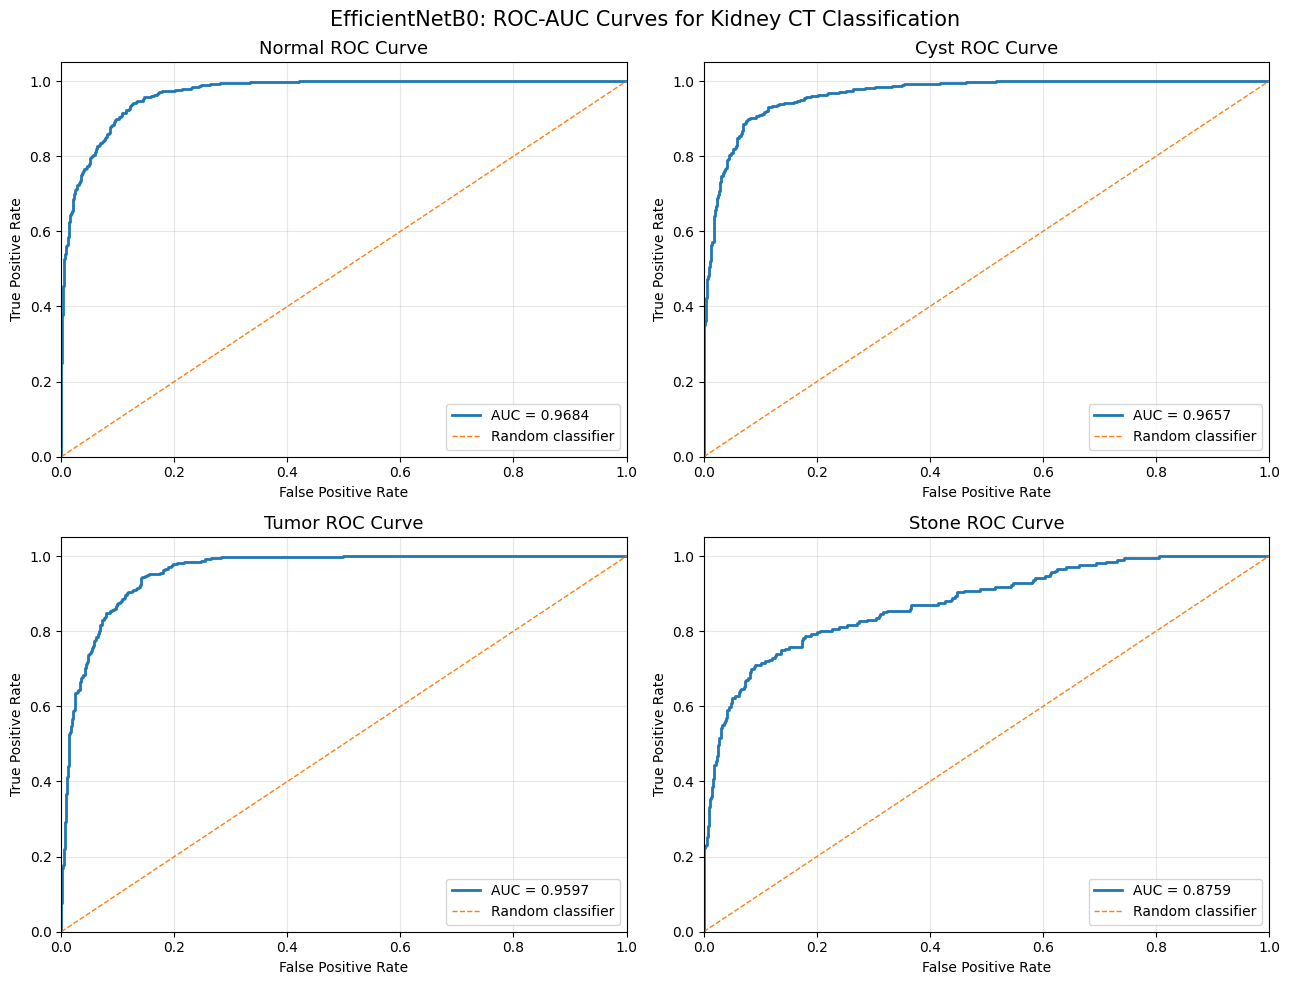


========== CLASS-WISE ROC-AUC ==========
Normal: 0.9684
Cyst: 0.9657
Tumor: 0.9597
Stone: 0.8759

Macro-average ROC-AUC: 0.9424
Macro-average ROC-AUC: 94.24%


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Convert actual class labels into one-hot format
y_true_one_hot = label_binarize(
    y_true,
    classes=[0, 1, 2, 3]
)

# Create a 2 x 2 grid
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

axes = axes.ravel()

class_auc_scores = {}

for i, class_name in enumerate(class_names):

    # Actual labels for this class: positive vs rest
    actual_binary = y_true_one_hot[:, i]

    # Predicted probability for this class
    predicted_probability = y_prob[:, i]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(
        actual_binary,
        predicted_probability
    )

    # Calculate AUC
    class_auc = auc(fpr, tpr)
    class_auc_scores[class_name] = class_auc

    # Plot
    axes[i].plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"AUC = {class_auc:.4f}"
    )

    # Random classifier reference line
    axes[i].plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1,
        label="Random classifier"
    )

    axes[i].set_title(
        f"{class_name} ROC Curve",
        fontsize=13
    )

    axes[i].set_xlabel("False Positive Rate")
    axes[i].set_ylabel("True Positive Rate")
    axes[i].set_xlim(0, 1)
    axes[i].set_ylim(0, 1.05)
    axes[i].legend(loc="lower right")
    axes[i].grid(alpha=0.3)

plt.suptitle(
    "EfficientNetB0: ROC-AUC Curves for Kidney CT Classification",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Print individual class AUC values
print("\n========== CLASS-WISE ROC-AUC ==========")

for class_name, score in class_auc_scores.items():
    print(f"{class_name}: {score:.4f}")

# Macro-average multiclass AUC
macro_auc = roc_auc_score(
    y_true_one_hot,
    y_prob,
    multi_class="ovr",
    average="macro"
)

print(f"\nMacro-average ROC-AUC: {macro_auc:.4f}")
print(f"Macro-average ROC-AUC: {macro_auc * 100:.2f}%")


              precision    recall  f1-score   support

      Normal     0.9470    0.5874    0.7251       761
        Cyst     0.7349    0.9156    0.8153       557
       Tumor     0.8756    0.5146    0.6483       342
       Stone     0.3200    0.7729    0.4526       207

    accuracy                         0.6926      1867
   macro avg     0.7194    0.6976    0.6603      1867
weighted avg     0.8011    0.6926    0.7077      1867



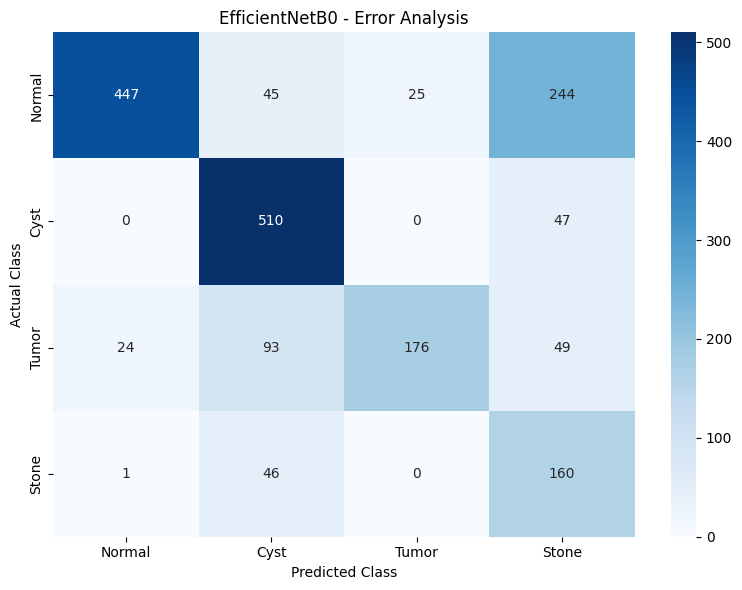

In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("EfficientNetB0 - Error Analysis")
plt.tight_layout()
plt.show()


In [ ]:

# Enable fine-tuning
base_model.trainable = True

# Keep early layers frozen; fine-tune later layers
fine_tune_at = 200

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a much smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))
print("Fine-tuning setup complete!")


Trainable layers: 30
Fine-tuning setup complete!


In [ ]:

fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_kidney_finetuned.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

fine_tune_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    class_weight=class_weights,
    callbacks=fine_tune_callbacks
)


Epoch 1/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 59s 130ms/step - accuracy: 0.8328 - loss: 0.4737 - val_accuracy: 0.7542 - val_loss: 0.5884 - learning_rate: 1.0000e-05
Epoch 2/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 40s 123ms/step - accuracy: 0.8530 - loss: 0.4014 - val_accuracy: 0.7809 - val_loss: 0.5176 - learning_rate: 1.0000e-05
Epoch 3/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 42s 133ms/step - accuracy: 0.8860 - loss: 0.3318 - val_accuracy: 0.8045 - val_loss: 0.4741 - learning_rate: 1.0000e-05
Epoch 4/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 46s 152ms/step - accuracy: 0.8999 - loss: 0.2854 - val_accuracy: 0.8586 - val_loss: 0.3623 - learning_rate: 1.0000e-05
Epoch 5/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 40s 125ms/step - accuracy: 0.9122 - loss: 0.2623 - val_accuracy: 0.8779 - val_loss: 0.3177 - learning_rate: 1.0000e-05
Epoch 6/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 46s 148ms/step - accuracy: 0.9191 - loss: 0.2279 - val_accuracy: 0.8881 - val_loss: 0.2888 - learning_rate: 1.0000e-05
Epoch 7/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 40s 12

In [ ]:

base_model.trainable = True

fine_tune_at = 200

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning enabled!")
print("Trainable backbone layers:",
      sum(layer.trainable for layer in base_model.layers))


Fine-tuning enabled!
Trainable backbone layers: 30


In [ ]:

fine_tune_loss, fine_tune_accuracy = model.evaluate(
    test_dataset,
    verbose=1
)

print("=" * 45)
print("EFFICIENTNETB0 AFTER FINE-TUNING")
print("=" * 45)
print(f"Test Accuracy: {fine_tune_accuracy * 100:.2f}%")
print(f"Test Loss:     {fine_tune_loss:.4f}")
print("=" * 45)


59/59 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.9207 - loss: 0.1981
EFFICIENTNETB0 AFTER FINE-TUNING
Test Accuracy: 92.07%
Test Loss:     0.1981


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score

# Generate predictions using the fine-tuned model
y_true_list = []
y_prob_list = []

for images, labels in test_dataset:
    probabilities = model.predict(images, verbose=0)
    y_true_list.extend(labels.numpy())
    y_prob_list.extend(probabilities)

y_true_finetuned = np.array(y_true_list)
y_pred_finetuned = np.argmax(np.array(y_prob_list), axis=1)

baseline_accuracy = 69.26 / 100  # Previously measured baseline
finetuned_accuracy = accuracy_score(
    y_true_finetuned,
    y_pred_finetuned
)

print("=" * 48)
print("       MODEL ACCURACY COMPARISON")
print("=" * 48)
print(f"Original EfficientNetB0 : {baseline_accuracy * 100:.2f}%")
print(f"Fine-tuned EfficientNetB0: {finetuned_accuracy * 100:.2f}%")
print(
    f"Change in accuracy      : "
    f"{(finetuned_accuracy - baseline_accuracy) * 100:+.2f} percentage points"
)
print("=" * 48)

       MODEL ACCURACY COMPARISON
Original EfficientNetB0 : 69.26%
Fine-tuned EfficientNetB0: 92.07%
Change in accuracy      : +22.81 percentage points


In [ ]:

from sklearn.metrics import classification_report

print(classification_report(
    y_true_finetuned,
    y_pred_finetuned,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    digits=4,
    zero_division=0
))


              precision    recall  f1-score   support

      Normal     0.9900    0.9067    0.9465       761
        Cyst     0.9086    0.9820    0.9439       557
       Tumor     0.9705    0.8655    0.9150       342
       Stone     0.7072    0.8986    0.7915       207

    accuracy                         0.9207      1867
   macro avg     0.8941    0.9132    0.8992      1867
weighted avg     0.9308    0.9207    0.9228      1867



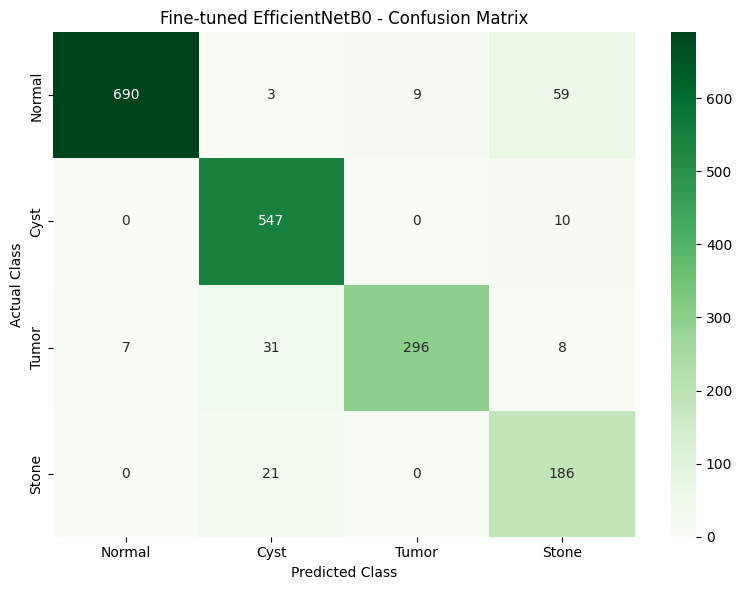

In [ ]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_finetuned = confusion_matrix(
    y_true_finetuned,
    y_pred_finetuned,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_finetuned,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Fine-tuned EfficientNetB0 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


In [ ]:

import os
from google.colab import drive

drive.mount('/content/drive')

final_model_path = (
    "/content/drive/MyDrive/kidney_finetuned_efficientnetb0.keras"
)

model.save(final_model_path)

print("Fine-tuned model saved successfully!")
print("Model path:", final_model_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fine-tuned model saved successfully!
Model path: /content/drive/MyDrive/kidney_finetuned_efficientnetb0.keras


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 46 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Saving Cyst- (4).jpg to Cyst- (4).jpg


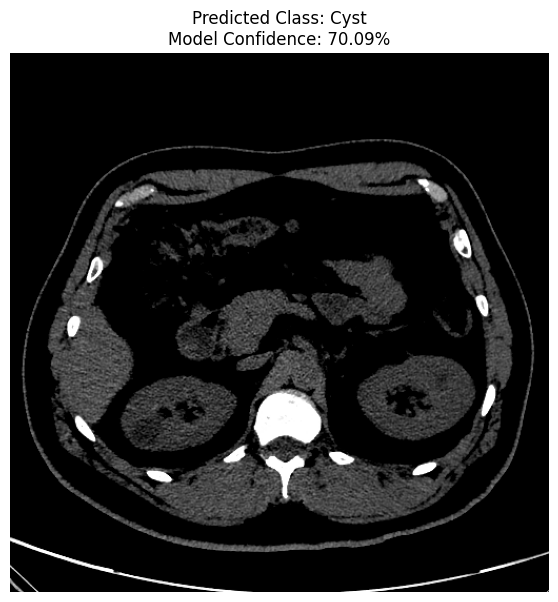

      KIDNEY CT CLASSIFICATION RESULT
Image: Cyst- (4).jpg
Predicted class: Cyst
Confidence: 70.09%

Class probabilities:
Normal: 0.00%
Cyst: 70.09%
Tumor: 0.00%
Stone: 29.91%


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

# Load the saved fine-tuned model
model = tf.keras.models.load_model(
    "/content/drive/MyDrive/kidney_finetuned_efficientnetb0.keras"
)

class_names = ["Normal", "Cyst", "Tumor", "Stone"]
IMG_SIZE = 224

# Upload an image
uploaded = files.upload()

for file_name in uploaded.keys():

    # Load original image
    original_image = Image.open(file_name).convert("RGB")

    # Preprocess exactly as used for classification
    resized_image = original_image.resize((IMG_SIZE, IMG_SIZE))

    image_array = np.array(
        resized_image,
        dtype=np.float32
    )

    input_image = np.expand_dims(image_array, axis=0)

    # Predict class probabilities
    probabilities = model.predict(
        input_image,
        verbose=0
    )[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = class_names[predicted_index]
    confidence = float(probabilities[predicted_index]) * 100

    # Display uploaded image and result
    plt.figure(figsize=(7, 7))
    plt.imshow(original_image)
    plt.axis("off")
    plt.title(
        f"Predicted Class: {predicted_class}\n"
        f"Model Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("=" * 45)
    print("      KIDNEY CT CLASSIFICATION RESULT")
    print("=" * 45)
    print("Image:", file_name)
    print("Predicted class:", predicted_class)
    print(f"Confidence: {confidence:.2f}%")
    print("\nClass probabilities:")

    for class_name, probability in zip(
        class_names, probabilities
    ):
        print(f"{class_name}: {probability * 100:.2f}%")

    print("=" * 45)


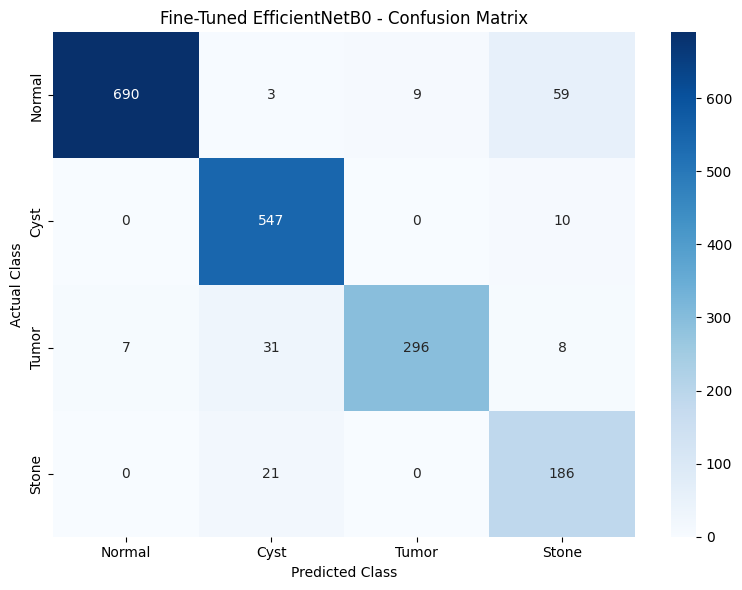

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Fine-Tuned EfficientNetB0 - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate the fine-tuned model on the test dataset
test_loss, test_accuracy = model.evaluate(
    test_dataset,
    verbose=1
)

# Generate predictions
y_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

y_prob = model.predict(test_dataset, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Calculate performance metrics
print("\n===== FINAL MODEL PERFORMANCE =====")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Precision: {precision_score(y_true, y_pred, average='weighted', zero_division=0) * 100:.2f}%")
print(f"Recall: {recall_score(y_true, y_pred, average='weighted', zero_division=0) * 100:.2f}%")
print(f"F1-Score: {f1_score(y_true, y_pred, average='weighted', zero_division=0) * 100:.2f}%")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))

59/59 ━━━━━━━━━━━━━━━━━━━━ 13s 116ms/step - accuracy: 0.9207 - loss: 0.1981
59/59 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step

===== FINAL MODEL PERFORMANCE =====
Test Loss: 0.1981
Test Accuracy: 92.07%
Precision: 93.08%
Recall: 92.07%
F1-Score: 92.28%

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Normal       0.99      0.91      0.95       761
        Cyst       0.91      0.98      0.94       557
       Tumor       0.97      0.87      0.91       342
       Stone       0.71      0.90      0.79       207

    accuracy                           0.92      1867
   macro avg       0.89      0.91      0.90      1867
weighted avg       0.93      0.92      0.92      1867

